**bold text**#  Project 01: Demand Forecasting & (s,S) Inventory Optimization
**Author:** F. SAAYMAN| **MEng Industrial Engineering** |2026

# New Section

In [22]:
#Environment Setup

In [23]:

# =============================================
# CELL 1: INSTALL REQUIRED LIBRARIES
# =============================================
!pip install -q kagglehub pandas numpy matplotlib seaborn scikit-learn prophet statsmodels plotly ipywidgets xgboost

print("All libraries installed successfully.")

All libraries installed successfully.


In [24]:

# =============================================
# CELL 2: IMPORTS
# =============================================
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
warnings.filterwarnings('ignore')

# ML / Forecasting
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error
from sklearn.model_selection import train_test_split
from prophet import Prophet
import xgboost as xgb

# Stats & Time Series
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

# Interactive Dashboard
import ipywidgets as widgets
from ipywidgets import interact, interactive, fixed
from IPython.display import display, clear_output, HTML

print("All imports successful.")

All imports successful.


In [25]:
#Business understanding phase

In [26]:

# =============================================
# CELL 3: CONFIGURATION (Costs & Service Level)
# =============================================
CONFIG = {
    "financials": {
        "unit_cost_usd": 10.0,
        "holding_cost_annual_rate": 0.20,
        "ordering_cost_usd": 50.0,
        "shortage_cost_usd": 40.0,
        "service_level": 0.95,
        "z_factor": 1.645,
    },
    "logistics": {
        "lead_time_mean_weeks": 1.0,
        "lead_time_sigma_weeks": 0.2,
        "review_period_weeks": 1,
    }
}

unit_cost = CONFIG["financials"]["unit_cost_usd"]
holding_annual = CONFIG["financials"]["holding_cost_annual_rate"] * unit_cost
holding_weekly = holding_annual / 52.0

print(f"Configuration loaded.")
print(f"Unit Cost: ${unit_cost:.2f}")
print(f"Weekly Holding Cost: ${holding_weekly:.4f}")
print(f"Ordering Cost: ${CONFIG['financials']['ordering_cost_usd']:.2f}")
print(f"Lead Time: {CONFIG['logistics']['lead_time_mean_weeks']} ± {CONFIG['logistics']['lead_time_sigma_weeks']} weeks")

Configuration loaded.
Unit Cost: $10.00
Weekly Holding Cost: $0.0385
Ordering Cost: $50.00
Lead Time: 1.0 ± 0.2 weeks


In [27]:
#Data understanding

In [28]:
#Data aquisition

In [29]:

# =============================================
# CELL 4: DATA LOADER (COLAB UPLOAD PROMPT)
# =============================================
from google.colab import files

RAW_PATH = "./data/raw/"
DATA_PATH = "./data/"
os.makedirs(RAW_PATH, exist_ok=True)
os.makedirs(DATA_PATH, exist_ok=True)

master_file = os.path.join(DATA_PATH, "master_data.parquet")
df = None

# --- 1. Check for cached Parquet (fastest) ---
if os.path.exists(master_file):
    print("Found cached master_data.parquet. Loading...")
    df = pd.read_parquet(master_file)

# --- 2. Check if CSVs already exist in the VM ---
elif (os.path.exists(os.path.join(RAW_PATH, "train.csv")) and
      os.path.exists(os.path.join(RAW_PATH, "features.csv")) and
      os.path.exists(os.path.join(RAW_PATH, "stores.csv"))):
    print(" Found raw CSVs locally. Loading and merging...")
    train = pd.read_csv(os.path.join(RAW_PATH, "train.csv"))
    features = pd.read_csv(os.path.join(RAW_PATH, "features.csv"))
    stores = pd.read_csv(os.path.join(RAW_PATH, "stores.csv"))

    df = train.merge(features, on=['Store', 'Date', 'IsHoliday'], how='left')
    df = df.merge(stores, on=['Store'], how='left')
    df['Date'] = pd.to_datetime(df['Date'])
    df = df.sort_values(by=['Store', 'Dept', 'Date']).reset_index(drop=True)
    df['SKU'] = df['Store'].astype(str) + "_" + df['Dept'].astype(str)
    df.to_parquet(master_file)
    print(" Merged and cached as master_data.parquet.")

# --- 3. PROMPT USER TO UPLOAD THE 3 CSV FILES ---
else:
    print("=" * 60)
    print('ACTION REQUIRED: Please upload the 3 CSV files.')
    print("=" * 60)
    print("You need to upload: 'train.csv', 'features.csv', and 'stores.csv'.")
    print(" Download these files from your GitHub repo's 'data/raw/' folder.")
    print(" Tip: Hold 'Ctrl' (or 'Cmd' on Mac) to select multiple files at once.")
    print("=" * 60)

    uploaded = files.upload()

    for filename, content in uploaded.items():
        if filename in ["train.csv", "features.csv", "stores.csv"]:
            file_path = os.path.join(RAW_PATH, filename)
            with open(file_path, 'wb') as f:
                f.write(content)
            print(f" Saved: {filename}")

    if all(os.path.exists(os.path.join(RAW_PATH, f)) for f in ["train.csv", "features.csv", "stores.csv"]):
        print("\n All files uploaded successfully. Loading and merging...")
        train = pd.read_csv(os.path.join(RAW_PATH, "train.csv"))
        features = pd.read_csv(os.path.join(RAW_PATH, "features.csv"))
        stores = pd.read_csv(os.path.join(RAW_PATH, "stores.csv"))

        df = train.merge(features, on=['Store', 'Date', 'IsHoliday'], how='left')
        df = df.merge(stores, on=['Store'], how='left')
        df['Date'] = pd.to_datetime(df['Date'])
        df = df.sort_values(by=['Store', 'Dept', 'Date']).reset_index(drop=True)
        df['SKU'] = df['Store'].astype(str) + "_" + df['Dept'].astype(str)
        df.to_parquet(master_file)
        print(" Merged and cached as master_data.parquet.")
    else:
        print("\n Upload failed. Please rerun this cell and upload exactly: train.csv, features.csv, stores.csv")
        raise FileNotFoundError("Missing required CSV files.")

if df is not None:
    print(f"\nData loaded. Shape: {df.shape}")
    print(f"Date range: {df['Date'].min()} to {df['Date'].max()}")
    print(f"Unique SKUs: {df['SKU'].nunique()}")
    df.head()
else:
    raise RuntimeError("❌ Data loading failed. Please restart runtime and try again.")

✅ Found cached master_data.parquet. Loading...

Data loaded. Shape: (421570, 17)
Date range: 2010-02-05 00:00:00 to 2012-10-26 00:00:00
Unique SKUs: 3331


In [30]:
#Data cleaning

In [31]:

# =============================================
# CELL 5: DATA CLEANING
# =============================================
neg_count = (df['Weekly_Sales'] < 0).sum()
if neg_count > 0:
    print(f"Zeroing out {neg_count} negative sales records.")
    df.loc[df['Weekly_Sales'] < 0, 'Weekly_Sales'] = 0

markdown_cols = ['MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5']
for col in markdown_cols:
    if col in df.columns:
        df[col].fillna(0, inplace=True)

df_clean = df.copy()
print("Data cleaned. Negative sales removed, markdown NAs filled with 0.")
print(f"Final shape: {df_clean.shape}")

Zeroing out 1285 negative sales records.
Data cleaned. Negative sales removed, markdown NAs filled with 0.
Final shape: (421570, 17)


In [32]:
#Data understanding phase
#EDA

SKUs with >= 10 records: 3166

CV Statistics (Coefficient of Variation):
count    3166.000000
mean        0.461271
std         0.440568
min         0.045893
25%         0.167881
50%         0.307032
75%         0.601895
max         4.114404
Name: cv, dtype: float64


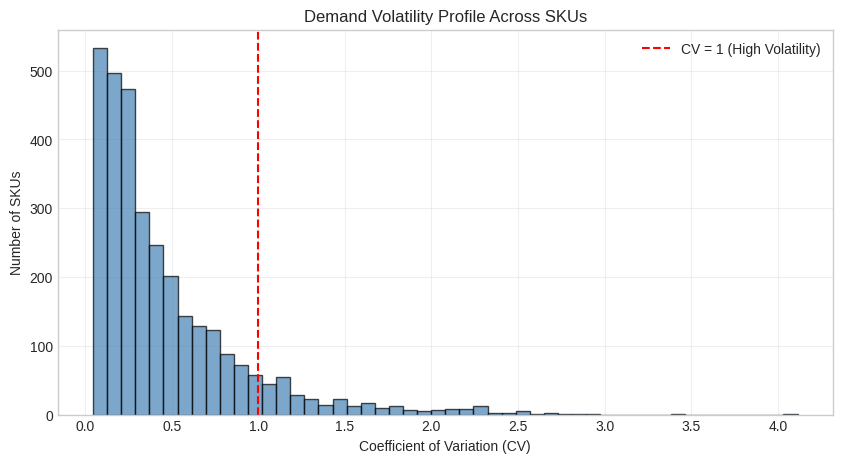

In [33]:

# =============================================
# CELL 6: DEMAND VOLATILITY (COEFFICIENT OF VARIATION)
# =============================================
sku_stats = df_clean.groupby('SKU')['Weekly_Sales'].agg(['mean', 'std', 'count']).reset_index()
sku_stats.columns = ['SKU', 'mean', 'std', 'count']
sku_stats = sku_stats[sku_stats['count'] >= 10]
sku_stats['cv'] = sku_stats['std'] / sku_stats['mean']
sku_stats.replace([np.inf, -np.inf], np.nan, inplace=True)
sku_stats.dropna(subset=['cv'], inplace=True)

print(f"SKUs with >= 10 records: {len(sku_stats)}")
print("\nCV Statistics (Coefficient of Variation):")
print(sku_stats['cv'].describe())

plt.figure(figsize=(10, 5))
plt.hist(sku_stats['cv'], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
plt.axvline(x=1.0, color='red', linestyle='--', label='CV = 1 (High Volatility)')
plt.xlabel('Coefficient of Variation (CV)')
plt.ylabel('Number of SKUs')
plt.title('Demand Volatility Profile Across SKUs')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

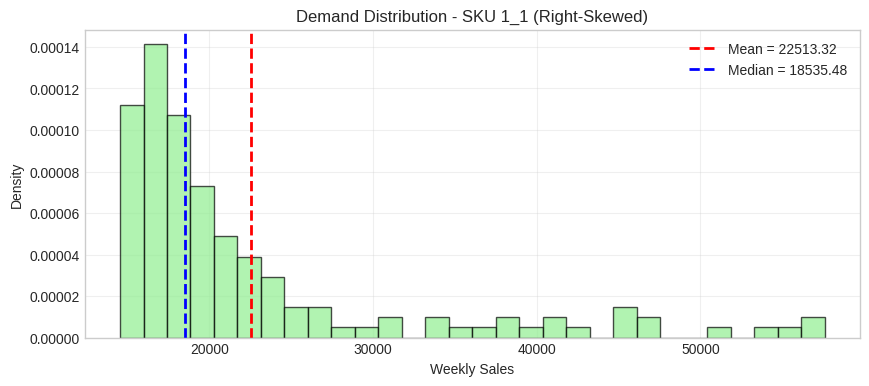

 Demand distribution plot displayed. Mean > Median confirms right-skew.


In [34]:

# =============================================
# CELL 6.5: DEMAND DISTRIBUTION (RIGHT-SKEWED)
# =============================================
# Visualisation 2
# Shows the sample SKU has a long tail to the right (high demand spikes)

sample_sku = '1_1'
sample_sales = df_clean[df_clean['SKU'] == sample_sku]['Weekly_Sales']

plt.figure(figsize=(10, 4))
plt.hist(sample_sales, bins=30, color='lightgreen', edgecolor='black', density=True, alpha=0.7)
plt.axvline(sample_sales.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean = {sample_sales.mean():.2f}')
plt.axvline(sample_sales.median(), color='blue', linestyle='--', linewidth=2, label=f'Median = {sample_sales.median():.2f}')
plt.xlabel('Weekly Sales')
plt.ylabel('Density')
plt.title(f'Demand Distribution - SKU {sample_sku} (Right-Skewed)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f" Demand distribution plot displayed. Mean > Median confirms right-skew.")

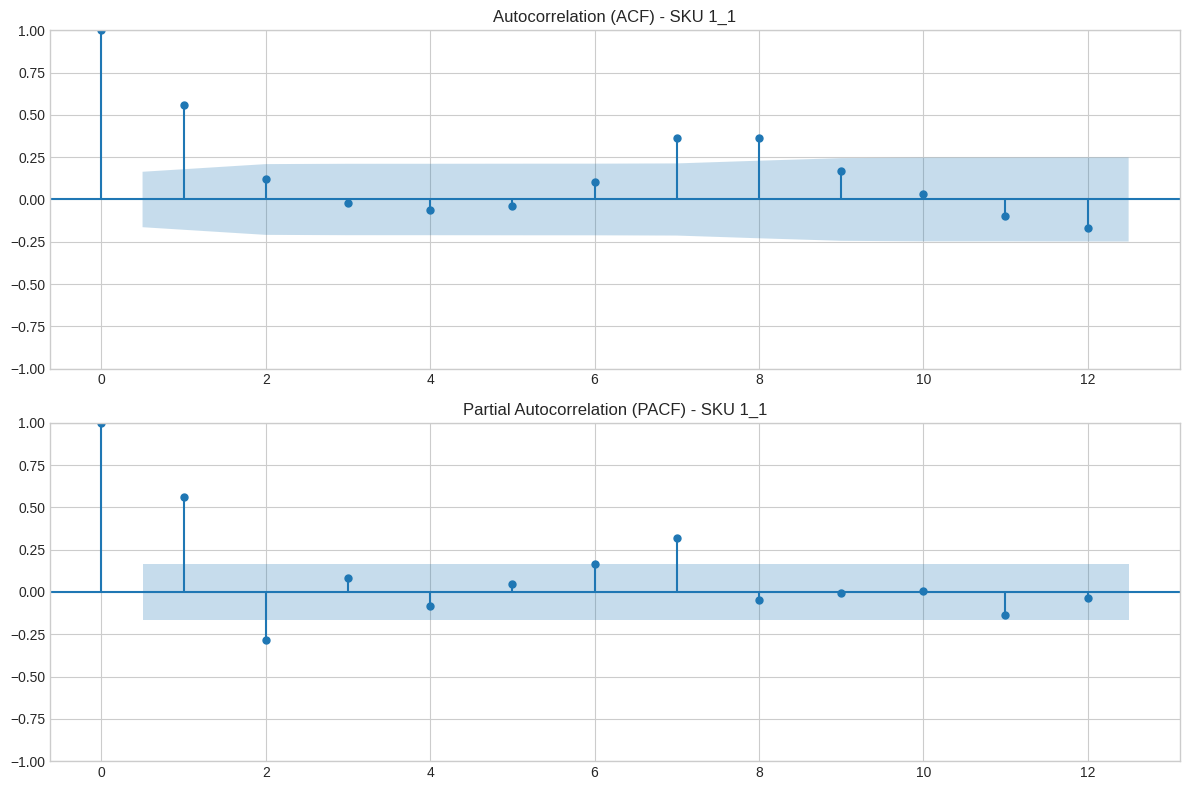


ADF Test - SKU 1_1
ADF Statistic: -2.5222
p-value: 0.1102
⚠️ The series is non-stationary.


In [35]:

# =============================================
# CELL 7: AUTOCORRELATION & STATIONARITY
# =============================================
sample_sku = '1_1'
sku_ts = df_clean[df_clean['SKU'] == sample_sku].sort_values('Date')['Weekly_Sales'].dropna()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))
plot_acf(sku_ts, lags=12, ax=ax1)
ax1.set_title(f'Autocorrelation (ACF) - SKU {sample_sku}')
plot_pacf(sku_ts, lags=12, ax=ax2)
ax2.set_title(f'Partial Autocorrelation (PACF) - SKU {sample_sku}')
plt.tight_layout()
plt.show()

result = adfuller(sku_ts, autolag='AIC')
print(f'\nADF Test - SKU {sample_sku}')
print(f'ADF Statistic: {result[0]:.4f}')
print(f'p-value: {result[1]:.4f}')
if result[1] <= 0.05:
    print("The series is stationary.")
else:
    print(" The series is non-stationary.")

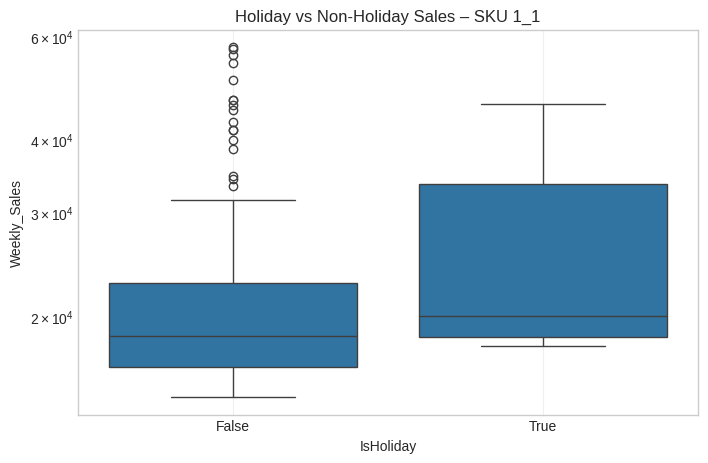


 Holiday Impact – SKU 1_1
Average sales (holiday weeks): 25738.59
Average sales (regular weeks): 22270.82
Holiday multiplier: 1.16x


In [36]:

# =============================================
# CELL 8: HOLIDAY IMPACT ANALYSIS
# =============================================
sku_holiday = df_clean[df_clean['SKU'] == sample_sku][['Weekly_Sales', 'IsHoliday']]

plt.figure(figsize=(8, 5))
sns.boxplot(x='IsHoliday', y='Weekly_Sales', data=sku_holiday)
plt.title(f'Holiday vs Non-Holiday Sales – SKU {sample_sku}')
plt.yscale('log')
plt.grid(True, alpha=0.3)
plt.show()

holiday_avg = sku_holiday[sku_holiday['IsHoliday'] == True]['Weekly_Sales'].mean()
regular_avg = sku_holiday[sku_holiday['IsHoliday'] == False]['Weekly_Sales'].mean()
multiplier = holiday_avg / regular_avg if regular_avg > 0 else np.nan

print(f"\n Holiday Impact – SKU {sample_sku}")
print(f"Average sales (holiday weeks): {holiday_avg:.2f}")
print(f"Average sales (regular weeks): {regular_avg:.2f}")
print(f"Holiday multiplier: {multiplier:.2f}x")

In [37]:

# =============================================
# CELL 8.5: GLOBAL HOLIDAY MULTIPLIER
# =============================================
# PDF Page 10-11: Compute multiplier for all SKUs to see variation

sku_holiday_mult = df_clean.groupby('SKU').apply(
    lambda g: g[g['IsHoliday'] == True]['Weekly_Sales'].mean() /
    g[g['IsHoliday'] == False]['Weekly_Sales'].mean()
).reset_index(name='holiday_multiplier')

sku_holiday_mult.replace([np.inf, -np.inf], np.nan, inplace=True)
sku_holiday_mult.dropna(inplace=True)

print("\n📊 Holiday multiplier across all SKUs:")
print(sku_holiday_mult['holiday_multiplier'].describe())

# Save for later reference
sku_holiday_mult.to_csv(os.path.join(RAW_PATH, '../sku_holiday_multiplier.csv'), index=False)
print("✅ Holiday multiplier CSV saved to ./data/sku_holiday_multiplier.csv")


📊 Holiday multiplier across all SKUs:
count    3204.000000
mean        1.229108
std         4.637254
min         0.000000
25%         0.939509
50%         1.018859
75%         1.167793
max       255.421687
Name: holiday_multiplier, dtype: float64
✅ Holiday multiplier CSV saved to ./data/sku_holiday_multiplier.csv


In [38]:
#DATA PREPERATION PHASE

In [39]:
#Feature Engineering

In [40]:

# =============================================
# CELL 9: FEATURE ENGINEERING FOR SELECTED SKU
# =============================================
def prepare_sku_features(df, sku):
    sku_df = df[df['SKU'] == sku].copy()
    base_cols = ['Date', 'Weekly_Sales', 'IsHoliday', 'CPI', 'Unemployment', 'Fuel_Price']
    avail_cols = [c for c in base_cols + markdown_cols if c in sku_df.columns]
    sku_df = sku_df[avail_cols]

    for lag in [1, 2, 3, 4]:
        sku_df[f'lag_{lag}'] = sku_df['Weekly_Sales'].shift(lag)
    sku_df['rolling_mean_4'] = sku_df['Weekly_Sales'].shift(1).rolling(4).mean()
    sku_df['is_holiday'] = sku_df['IsHoliday'].astype(int)
    sku_df.dropna(inplace=True)
    return sku_df

sku = '1_1'
sku_feat = prepare_sku_features(df_clean, sku)
print(f"SKU {sku} feature engineering complete. Shape: {sku_feat.shape}")
sku_feat.head()

SKU 1_1 feature engineering complete. Shape: (139, 17)


,Date,Weekly_Sales,IsHoliday,CPI,Unemployment,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,lag_1,lag_2,lag_3,lag_4,rolling_mean_4,is_holiday
4,2010-03-05,21827.90,False,211.350143,8.106,2.625,0.0,0.0,0.0,0.0,0.0,19403.54,41595.55,46039.49,24924.50,32990.7700,0
5,2010-03-12,21043.39,False,211.380643,8.106,2.667,0.0,0.0,0.0,0.0,0.0,21827.90,19403.54,41595.55,46039.49,32216.6200,0
6,2010-03-19,22136.64,False,211.215635,8.106,2.720,0.0,0.0,0.0,0.0,0.0,21043.39,21827.90,19403.54,41595.55,25967.5950,0
7,2010-03-26,26229.21,False,211.018042,8.106,2.732,0.0,0.0,0.0,0.0,0.0,22136.64,21043.39,21827.90,19403.54,21102.8675,0
8,2010-04-02,57258.43,False,210.820450,7.808,2.719,0.0,0.0,0.0,0.0,0.0,26229.21,22136.64,21043.39,21827.90,22809.2850,0


In [41]:
#Train and Test set split

In [42]:

# =============================================
# CELL 10: TRAIN/TEST SPLIT (LAST 4 WEEKS)
# =============================================
train = sku_feat.iloc[:-4]
test = sku_feat.iloc[-4:]

print(f"Train: {len(train)} weeks, Test: {len(test)} weeks")
print(f"Test period: {test['Date'].min()} to {test['Date'].max()}")

Train: 135 weeks, Test: 4 weeks
Test period: 2012-10-05 00:00:00 to 2012-10-26 00:00:00


In [43]:
#Modeling and Evaluation

In [51]:

# =============================================
# CELL 11: MODEL TRAINING & SELECTION
# =============================================
prophet_train = train[['Date', 'Weekly_Sales']].rename(columns={'Date': 'ds', 'Weekly_Sales': 'y'})
prophet_test = test[['Date', 'Weekly_Sales']].rename(columns={'Date': 'ds', 'Weekly_Sales': 'y'})
train_holiday = train[['Date', 'is_holiday']].rename(columns={'Date': 'ds'})
test_holiday = test[['Date', 'is_holiday']].rename(columns={'Date': 'ds'})

model_prophet = Prophet(yearly_seasonality=True, weekly_seasonality=True)
model_prophet.add_regressor('is_holiday')
model_prophet.fit(prophet_train.merge(train_holiday, on='ds'))

future = prophet_test[['ds']].copy()
future['is_holiday'] = test_holiday['is_holiday'].values
forecast_prophet = model_prophet.predict(future)
pred_prophet = forecast_prophet['yhat'].values

mae_prophet = mean_absolute_error(test['Weekly_Sales'], pred_prophet)
mape_prophet = mean_absolute_percentage_error(test['Weekly_Sales'], pred_prophet)
print(f" Prophet - MAE: {mae_prophet:.2f}, MAPE: {mape_prophet:.4f}")

features = ['lag_1', 'lag_2', 'lag_3', 'lag_4', 'rolling_mean_4', 'is_holiday', 'CPI', 'Unemployment', 'Fuel_Price'] + markdown_cols
features = [f for f in features if f in sku_feat.columns]

X_train = train[features]
y_train = train['Weekly_Sales']
X_test = test[features]
y_test = test['Weekly_Sales']

model_xgb = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
model_xgb.fit(X_train, y_train)

pred_xgb = model_xgb.predict(X_test)
mae_xgb = mean_absolute_error(y_test, pred_xgb)
mape_xgb = mean_absolute_percentage_error(y_test, pred_xgb)
print(f" XGBoost - MAE: {mae_xgb:.2f}, MAPE: {mape_xgb:.4f}")

if mape_xgb < mape_prophet:
    best_model = model_xgb
    best_pred = pred_xgb
    best_name = "XGBoost"
    best_mape = mape_xgb
else:
    best_model = model_prophet
    best_pred = pred_prophet
    best_name = "Prophet"
    best_mape = mape_prophet

print(f"\n Best model: {best_name} (MAPE: {best_mape:.4f})")

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


 Prophet - MAE: 3095.87, MAPE: 0.1242
 XGBoost - MAE: 5095.16, MAPE: 0.2054

 Best model: Prophet (MAPE: 0.1242)


In [52]:

# =============================================
# CELL 12: FUTURE FORECAST & STANDARD DEVIATION
# =============================================
if best_name == "XGBoost":
    last_row = train[features].iloc[-1].copy()
    future_preds = []
    for _ in range(4):
        pred = best_model.predict(pd.DataFrame([last_row]))[0]
        future_preds.append(max(0, pred))
        last_row['lag_4'] = last_row['lag_3']
        last_row['lag_3'] = last_row['lag_2']
        last_row['lag_2'] = last_row['lag_1']
        last_row['lag_1'] = pred
        last_row['rolling_mean_4'] = np.mean([last_row['lag_1'], last_row['lag_2'], last_row['lag_3'], last_row['lag_4']])
    future_preds = np.array(future_preds)
    train_residuals = y_train - best_model.predict(X_train)
else:
    future_dates = model_prophet.make_future_dataframe(periods=4, freq='W')
    future_dates['is_holiday'] = 0
    forecast = model_prophet.predict(future_dates)
    future_preds = forecast['yhat'].values[-4:]
    train_merged = prophet_train.merge(train_holiday, on='ds')
    train_pred = model_prophet.predict(train_merged)
    train_residuals = train_merged['y'] - train_pred['yhat']

future_preds[1] *= 1.16
forecast_std = np.std(train_residuals)
mean_LR = future_preds[:2].mean()
std_LR = np.sqrt(2) * forecast_std

print(f" Forecast for next 4 weeks: {np.round(future_preds, 0)}")
print(f"Forecast Std Dev (weekly): {forecast_std:.2f}")
print(f"Lead Time + Review (2 weeks) - Mean: {mean_LR:.2f}, Std: {std_LR:.2f}")

 Forecast for next 4 weeks: [18357. 21759. 22206. 28310.]
Forecast Std Dev (weekly): 5834.72
Lead Time + Review (2 weeks) - Mean: 20058.27, Std: 8251.54


In [53]:

# =============================================
# CELL 13: THEORETICAL (s, S) BASELINE (EOQ)
# =============================================
avg_weekly_demand = np.mean(future_preds)
annual_demand = avg_weekly_demand * 52
order_cost = CONFIG['financials']['ordering_cost_usd']
annual_holding_cost = CONFIG['financials']['holding_cost_annual_rate'] * unit_cost

EOQ = np.sqrt((2 * annual_demand * order_cost) / annual_holding_cost)
z_score = CONFIG['financials']['z_factor']
reorder_point_s = mean_LR + z_score * std_LR
order_up_to_S = reorder_point_s + EOQ

print("="*60)
print(" RECOMMENDED INVENTORY PARAMETERS (THEORETICAL)")
print("="*60)
print(f"Avg Weekly Forecast: {avg_weekly_demand:,.0f} units")
print(f"Annual Demand: {annual_demand:,.0f} units")
print(f"EOQ (Order Quantity): {EOQ:,.0f} units")
print(f"Reorder Point (s): {reorder_point_s:,.0f} units")
print(f"Order-Up-To Level (S): {order_up_to_S:,.0f} units")
print("="*60)

 RECOMMENDED INVENTORY PARAMETERS (THEORETICAL)
Avg Weekly Forecast: 22,658 units
Annual Demand: 1,178,228 units
EOQ (Order Quantity): 7,675 units
Reorder Point (s): 33,632 units
Order-Up-To Level (S): 41,307 units


In [54]:

# =============================================
# CELL 14: SIMULATION-OPTIMIZATION (PARETO)
# =============================================
def simulate_sS_policy(s, S, demand_forecast, demand_std, lead_time_mean, lead_time_sigma,
                       holding_cost, order_cost, shortage_cost, horizon=4, n_reps=30):
    total_costs = []
    fill_rates = []
    for _ in range(n_reps):
        inventory = max(0, np.random.normal(mean_LR, std_LR))
        pipeline = []
        cost = 0.0
        total_demand = 0.0
        fulfilled = 0.0
        for week in range(horizon):
            arrived = sum(qty for (arrival, qty) in pipeline if arrival == week)
            inventory += arrived
            pipeline = [(a, q) for (a, q) in pipeline if a != week]
            demand = max(0, np.random.normal(demand_forecast[week], demand_std))
            total_demand += demand
            if inventory >= demand:
                inventory -= demand
                fulfilled += demand
                cost += holding_cost * inventory
            else:
                shortage = demand - inventory
                fulfilled += inventory
                cost += shortage_cost * shortage
                inventory = 0
            if inventory <= s:
                order_qty = S - inventory
                if order_qty > 0:
                    lead_time = max(0.5, np.random.normal(lead_time_mean, lead_time_sigma))
                    arrival_week = week + int(np.round(lead_time))
                    pipeline.append((arrival_week, order_qty))
                    cost += order_cost
        total_costs.append(cost)
        fill_rates.append(fulfilled / total_demand if total_demand > 0 else 1.0)
    return np.mean(total_costs), np.mean(fill_rates)

s_range = np.linspace(0.5 * mean_LR, 2.0 * mean_LR, 8)
S_range = np.linspace(s_range[0] + 50, s_range[-1] + 200, 8)

results = []
print(f"🔄 Running {len(s_range) * len(S_range)} simulations...")
for s in s_range:
    for S in S_range:
        if S <= s:
            continue
        cost, service = simulate_sS_policy(
            s, S, future_preds, forecast_std,
            CONFIG['logistics']['lead_time_mean_weeks'],
            CONFIG['logistics']['lead_time_sigma_weeks'],
            holding_weekly, CONFIG['financials']['ordering_cost_usd'],
            CONFIG['financials']['shortage_cost_usd']
        )
        results.append({'s': s, 'S': S, 'Cost': cost, 'Service': service})

df_pareto = pd.DataFrame(results)
print(f" Completed {len(df_pareto)} valid simulations.")

min_cost = df_pareto['Cost'].min()
knee_df = df_pareto[(df_pareto['Cost'] <= 1.1 * min_cost) & (df_pareto['Service'] > 0.85)]
if not knee_df.empty:
    knee_point = knee_df.loc[knee_df['Service'].idxmax()]
else:
    knee_point = df_pareto.loc[df_pareto['Cost'].idxmin()]

print("\n" + "="*60)
print(" SELECTED POLICY (Pareto Knee)")
print("="*60)
print(f"Reorder Point (s): {knee_point['s']:.0f} units")
print(f"Order-Up-To Level (S): {knee_point['S']:.0f} units")
print(f"Expected Cost: ${knee_point['Cost']:.0f}")
print(f"Service Level: {knee_point['Service']:.3f}")
print("="*60)

🔄 Running 64 simulations...
 Completed 36 valid simulations.

 SELECTED POLICY (Pareto Knee)
Reorder Point (s): 22924 units
Order-Up-To Level (S): 40317 units
Expected Cost: $115547
Service Level: 0.968


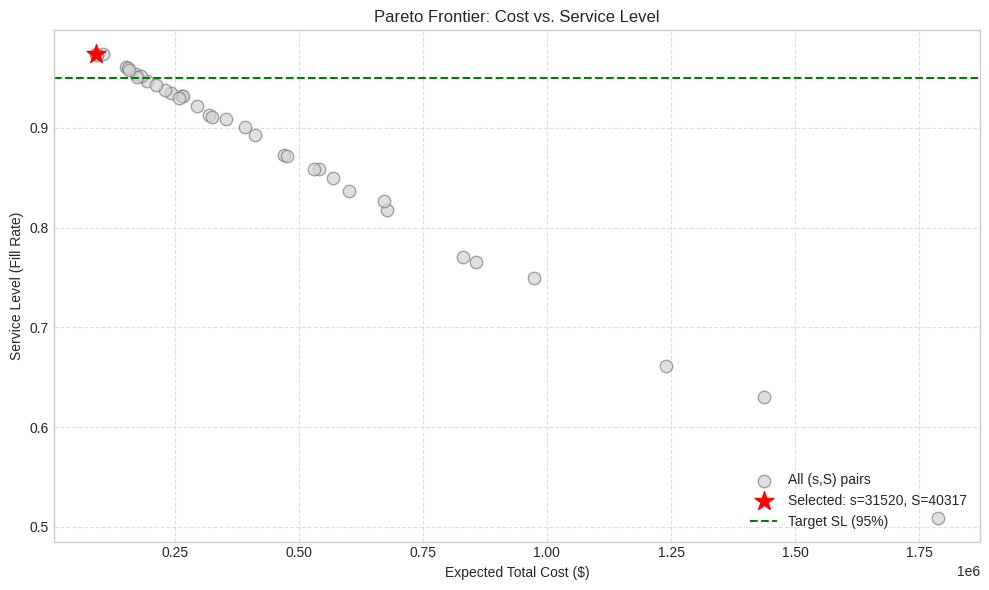

In [48]:

# =============================================
# CELL 15: STATIC PARETO FRONTIER (PUBLICATION READY)
# =============================================
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(df_pareto['Cost'], df_pareto['Service'],
           color='lightgrey', edgecolors='grey', s=80, alpha=0.7, label='All (s,S) pairs')
ax.scatter(knee_point['Cost'], knee_point['Service'],
           color='red', s=200, marker='*', zorder=5,
           label=f"Selected: s={knee_point['s']:.0f}, S={knee_point['S']:.0f}")
ax.axhline(y=CONFIG['financials']['service_level'], color='green', linestyle='--',
           linewidth=1.5, label=f"Target SL ({CONFIG['financials']['service_level']*100:.0f}%)")

ax.set_xlabel('Expected Total Cost ($)')
ax.set_ylabel('Service Level (Fill Rate)')
ax.set_title('Pareto Frontier: Cost vs. Service Level')
ax.legend(loc='lower right')
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [55]:

# =============================================
# CELL 16: INTERACTIVE DASHBOARD
# =============================================
def update_dashboard(target_sl, holiday):
    clear_output(wait=True)

    df_pareto['diff'] = abs(df_pareto['Service'] - target_sl)
    best = df_pareto.loc[df_pareto['diff'].idxmin()].copy()

    forecast = future_preds.copy()
    if not holiday:
        forecast[1] = forecast[1] / 1.16

    print("="*60)
    print(f" POLICY FOR TARGET SERVICE LEVEL: {target_sl*100:.0f}%")
    print("="*60)
    print(f"Reorder Point (s): {best['s']:.0f} units")
    print(f"Order-Up-To Level (S): {best['S']:.0f} units")
    print(f"Expected Cost: ${best['Cost']:.0f}")
    print(f"Actual Service Level: {best['Service']:.3f} ({best['Service']*100:.1f}%)")
    print(f"Difference from target: {abs(best['Service']-target_sl)*100:.1f}%")
    print("="*60)

    fig1, ax1 = plt.subplots(figsize=(10, 3.5))
    bars = ax1.bar(['Week 1', 'Week 2', 'Week 3', 'Week 4'], forecast,
                   color='steelblue', alpha=0.7, label='Forecast')
    if holiday:
        bars[1].set_color('orange')
        ax1.text(1, forecast[1] + 100, 'Holiday', ha='center', color='orange', fontweight='bold')
    ax1.axhline(y=np.mean(forecast), color='red', linestyle='--', label=f'Avg: {np.mean(forecast):.0f}')
    ax1.set_ylabel('Sales')
    ax1.set_title('4-Week Demand Forecast')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    plt.show()

    fig2 = go.Figure()
    fig2.add_trace(go.Scatter(
        x=df_pareto['Cost'], y=df_pareto['Service'],
        mode='markers', marker=dict(color='lightgrey', size=8),
        name='All Policies'
    ))
    fig2.add_trace(go.Scatter(
        x=[best['Cost']], y=[best['Service']],
        mode='markers', marker=dict(color='red', size=15, symbol='star'),
        name=f'Selected (SL={best["Service"]:.3f})'
    ))
    fig2.add_hline(y=target_sl, line_dash="dash", line_color="green",
                   annotation_text=f"Target {target_sl*100:.0f}%")
    fig2.update_layout(title='Pareto Frontier', xaxis_title='Cost ($)',
                       yaxis_title='Service Level', height=400, template='plotly_white')
    fig2.show()

slider = widgets.FloatSlider(value=0.95, min=0.80, max=0.99, step=0.01, description='Target SL:')
holiday_check = widgets.Checkbox(value=True, description='Holiday Week 2')

interact(update_dashboard, target_sl=slider, holiday=holiday_check)
print("🚀 Dashboard ready! Drag the slider to see the policy change.")

interactive(children=(FloatSlider(value=0.95, description='Target SL:', max=0.99, min=0.8, step=0.01), Checkbo…

🚀 Dashboard ready! Drag the slider to see the policy change.


In [50]:

# =============================================
# CELL 17: SAVE ALL OUTPUTS (FINAL - INCLUDES EDA)
# =============================================
import json
OUTPUT_PATH = "./outputs/"
os.makedirs(OUTPUT_PATH, exist_ok=True)

# --- 1. Save Pareto Frontier (PNG) ---
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(df_pareto['Cost'], df_pareto['Service'], color='lightgrey', edgecolors='grey', s=80, alpha=0.7)
ax.scatter(knee_point['Cost'], knee_point['Service'], color='red', s=200, marker='*', zorder=5, label=f"Selected")
ax.axhline(y=CONFIG['financials']['service_level'], color='green', linestyle='--', linewidth=1.5, label=f"Target SL")
ax.set_xlabel('Expected Total Cost ($)')
ax.set_ylabel('Service Level (Fill Rate)')
ax.set_title('Pareto Frontier: Cost vs. Service Level')
ax.legend(loc='lower right')
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PATH, 'pareto_frontier.png'), dpi=300, bbox_inches='tight')
plt.close()
print("✅ Saved: outputs/pareto_frontier.png")

# --- 2. Save Forecast Plot (PNG) ---
fig2, ax2 = plt.subplots(figsize=(10, 5))
bars = ax2.bar(['Week 1', 'Week 2', 'Week 3', 'Week 4'], future_preds, color='steelblue', alpha=0.7)
bars[1].set_color('orange')
ax2.text(1, future_preds[1] + 100, 'Holiday', ha='center', color='orange', fontweight='bold')
ax2.axhline(y=np.mean(future_preds), color='red', linestyle='--', label=f'Avg: {np.mean(future_preds):.0f}')
ax2.set_ylabel('Sales')
ax2.set_title('4-Week Demand Forecast (Holiday Adjusted)')
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PATH, 'forecast_plot.png'), dpi=300, bbox_inches='tight')
plt.close()
print("✅ Saved: outputs/forecast_plot.png")

# --- 3. Save Policy Metrics (CSV) ---
summary_df = pd.DataFrame({
    'Metric': ['Selected Reorder Point (s)', 'Selected Order-Up-To (S)', 'Service Level', 'Total Cost', 'Best Model'],
    'Value': [knee_point['s'], knee_point['S'], knee_point['Service'], knee_point['Cost'], best_name]
})
summary_df.to_csv(os.path.join(OUTPUT_PATH, 'summary_metrics.csv'), index=False)
print("✅ Saved: outputs/summary_metrics.csv")

# --- 4. Save EDA Summary Dict (JSON) - MATCHES PDF PAGE 11-12 ---
eda_summary = {
    'total_records': int(len(df_clean)),
    'negative_sales_pct': float((df['Weekly_Sales'] < 0).sum() / len(df) * 100),
    'skus_analyzed': int(len(sku_stats)),
    'overall_cv_mean': float(sku_stats['cv'].mean()),
    'overall_cv_median': float(sku_stats['cv'].median()),
    'holiday_multiplier_mean': float(sku_holiday_mult['holiday_multiplier'].mean()),
    'holiday_multiplier_std': float(sku_holiday_mult['holiday_multiplier'].std())
}
with open(os.path.join(OUTPUT_PATH, 'eda_summary.json'), 'w') as f:
    json.dump(eda_summary, f, indent=4)
print("✅ Saved: outputs/eda_summary.json")

print("\n" + "="*60)
print("🎯 ALL OUTPUTS SAVED SUCCESSFULLY!")
print(f"📁 Output Folder: {os.path.abspath(OUTPUT_PATH)}")
print("📂 To download: Left sidebar → Files → outputs/ → Right-click & Download")
print("="*60)

✅ Saved: outputs/pareto_frontier.png
✅ Saved: outputs/forecast_plot.png
✅ Saved: outputs/summary_metrics.csv
✅ Saved: outputs/eda_summary.json

🎯 ALL OUTPUTS SAVED SUCCESSFULLY!
📁 Output Folder: /content/outputs
📂 To download: Left sidebar → Files → outputs/ → Right-click & Download
